In [3]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from PIL import Image
import matplotlib.pyplot as plt

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch:", torch.__version__, "| urządzenie:", device)

PyTorch: 2.14.1+cpu | urządzenie: cpu


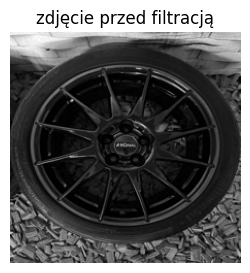

In [4]:
pil = Image.open("felga.png").convert("L").convert("RGB").resize((224, 224))

rgb = torch.from_numpy(np.array(pil)).float().permute(2,0,1).unsqueeze(0) / 255.0  # [1,3,H,W]
gray = rgb.mean(1, keepdim=True)  # [1,1,H,W]
plt.figure(figsize=(3,3)); plt.imshow(gray[0,0], cmap="gray"); plt.axis("off"); plt.title("zdjęcie przed filtracją"); plt.show()

In [5]:
def out_dim(in_size, k, s=1, p=0, d=1):
    return (in_size + 2*p - d*(k-1) - 1)//s + 1

IN = 32
configs = [
    dict(k=3, s=1, p=1, d=1),
    dict(k=3, s=2, p=1, d=1),
    dict(k=5, s=1, p=2, d=1),
    dict(k=3, s=1, p=2, d=2),
    dict(k=7, s=2, p=3, d=1),
]
print(f"in={IN}")
print(f"{'k':>2} {'s':>2} {'p':>2} {'d':>2} | {'wzór':>5} {'Conv2d':>7}")
x = torch.randn(1, 3, IN, IN)
for c in configs:
    conv = nn.Conv2d(3, 8, kernel_size=c['k'], stride=c['s'], padding=c['p'], dilation=c['d'])
    real = conv(x).shape[-1]
    formula = out_dim(IN, **c)
    ok = '✓' if real == formula else '✗'
    print(f"{c['k']:>2} {c['s']:>2} {c['p']:>2} {c['d']:>2} | {formula:>5} {real:>7}  {ok}")

in=32
 k  s  p  d |  wzór  Conv2d
 3  1  1  1 |    32      32  ✓
 3  2  1  1 |    16      16  ✓
 5  1  2  1 |    32      32  ✓
 3  1  2  2 |    32      32  ✓
 7  2  3  1 |    16      16  ✓


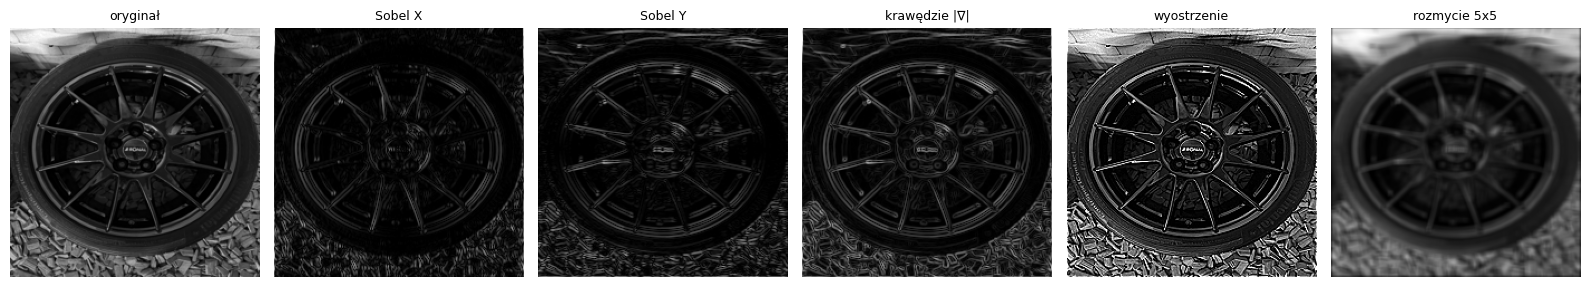

In [6]:
def kernel(t):
    return torch.tensor(t, dtype=torch.float32).view(1,1,*np.array(t).shape)

sobel_x = kernel([[-1,0,1],[-2,0,2],[-1,0,1]])
sobel_y = kernel([[-1,-2,-1],[0,0,0],[1,2,1]])
sharpen = kernel([[0,-1,0],[-1,5,-1],[0,-1,0]])
blur = torch.ones(1,1,5,5)/25.0

gx = F.conv2d(gray, sobel_x, padding=1)
gy = F.conv2d(gray, sobel_y, padding=1)
edges = (gx**2 + gy**2).sqrt()
results = {
    "oryginał": gray,
    "Sobel X": gx.abs(),
    "Sobel Y": gy.abs(),
    "krawędzie |∇|": edges,
    "wyostrzenie": F.conv2d(gray, sharpen, padding=1).clamp(0,1),
    "rozmycie 5x5": F.conv2d(gray, blur, padding=2),
}
fig, axes = plt.subplots(1, len(results), figsize=(16, 3))
for ax, (name, out) in zip(axes, results.items()):
    m = out[0,0].detach()
    ax.imshow(m, cmap="gray"); ax.set_title(name, fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

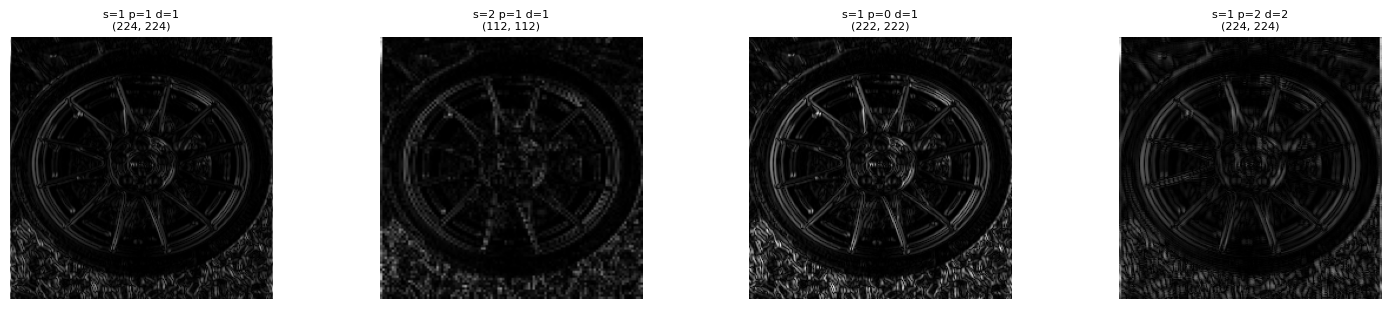

In [7]:
settings = [
    dict(stride=1, padding=1, dilation=1),  # zachowuje rozmiar
    dict(stride=2, padding=1, dilation=1),  # zmniejsza ~2x
    dict(stride=1, padding=0, dilation=1),  # brak paddingu
    dict(stride=1, padding=2, dilation=2),  # dilation - większe pole
]
fig, axes = plt.subplots(1, len(settings), figsize=(15, 3.2))
for ax, s in zip(axes, settings):
    out = F.conv2d(gray, sobel_x, **s)
    ax.imshow(out[0,0].abs().detach(), cmap="gray")
    ax.set_title(f"s={s['stride']} p={s['padding']} d={s['dilation']}\n{tuple(out.shape[-2:])}", fontsize=8)
    ax.axis("off")
plt.tight_layout(); plt.show()

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 113MB/s]


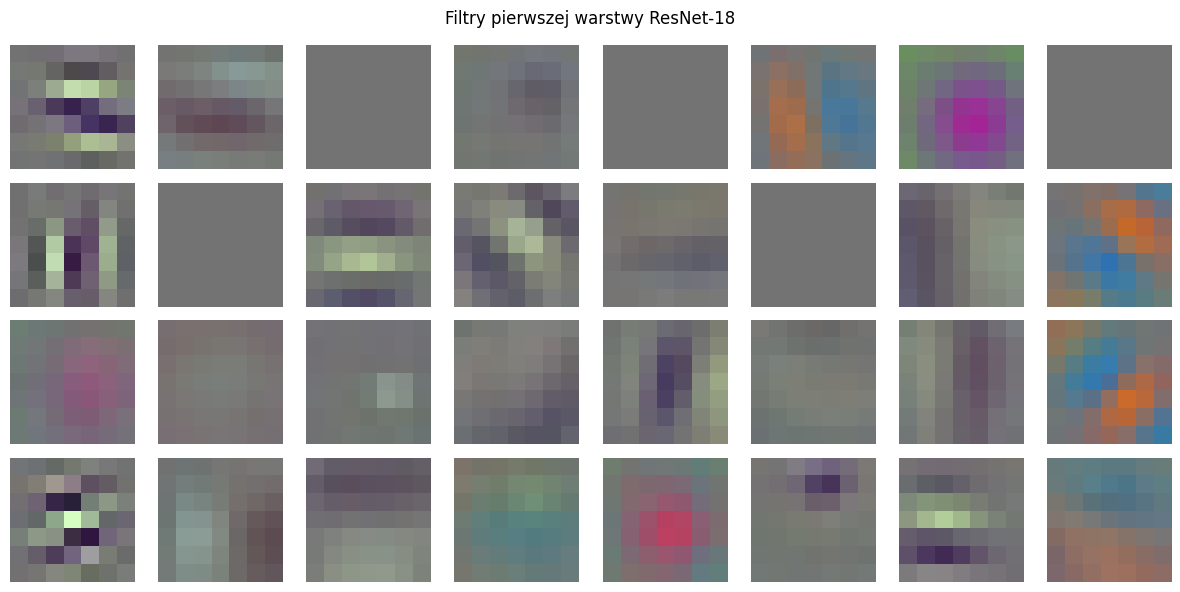

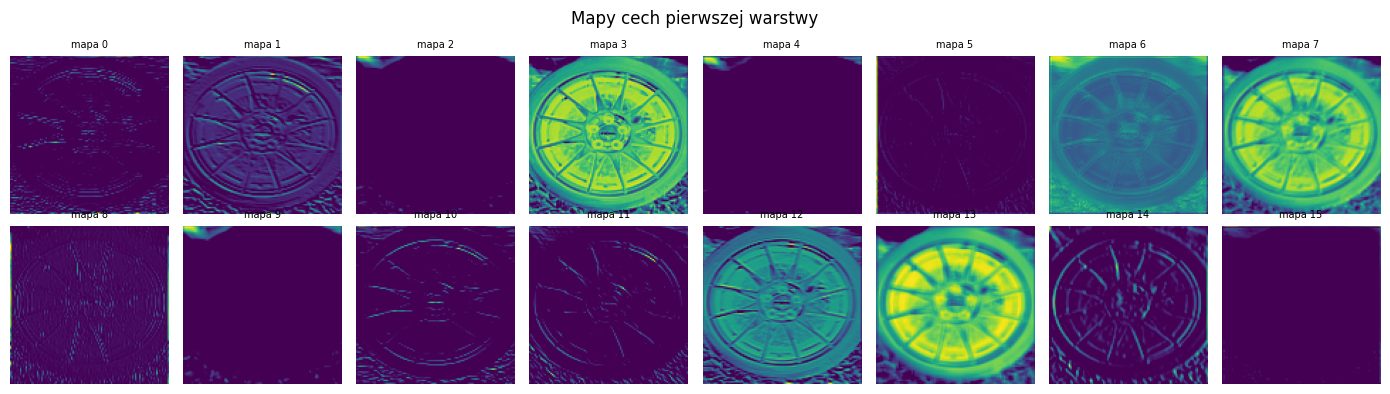

In [8]:
from torchvision.models import resnet18, ResNet18_Weights
weights = ResNet18_Weights.DEFAULT
model = resnet18(weights=weights).to(device).eval()

# 5a. wagi pierwszej warstwy jako obrazki RGB
W = model.conv1.weight.data.clone().cpu()  # [64,3,7,7]
Wn = (W - W.min()) / (W.max() - W.min())
fig, axes = plt.subplots(4, 8, figsize=(12, 6))
for i, ax in enumerate(axes.flat):
    ax.imshow(Wn[i].permute(1,2,0)); ax.axis("off")
fig.suptitle("Filtry pierwszej warstwy ResNet-18"); plt.tight_layout(); plt.show()

# 5b. mapy cech dla naszego zdjęcia
preprocess = weights.transforms()
x = preprocess(pil).unsqueeze(0).to(device)
with torch.no_grad():
    fmaps = torch.relu(model.conv1(x))[0].cpu()  # [64, H, W]
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(fmaps[i], cmap="viridis"); ax.set_title(f"mapa {i}", fontsize=7); ax.axis("off")
fig.suptitle("Mapy cech pierwszej warstwy"); plt.tight_layout(); plt.show()

Box 3×3 | suma wag: 1.0 | rozmiar: (224, 224)
Box 5×5 | suma wag: 1.0 | rozmiar: (224, 224)
Gaussian 5×5 | suma wag: 1.0 | rozmiar: (224, 224)


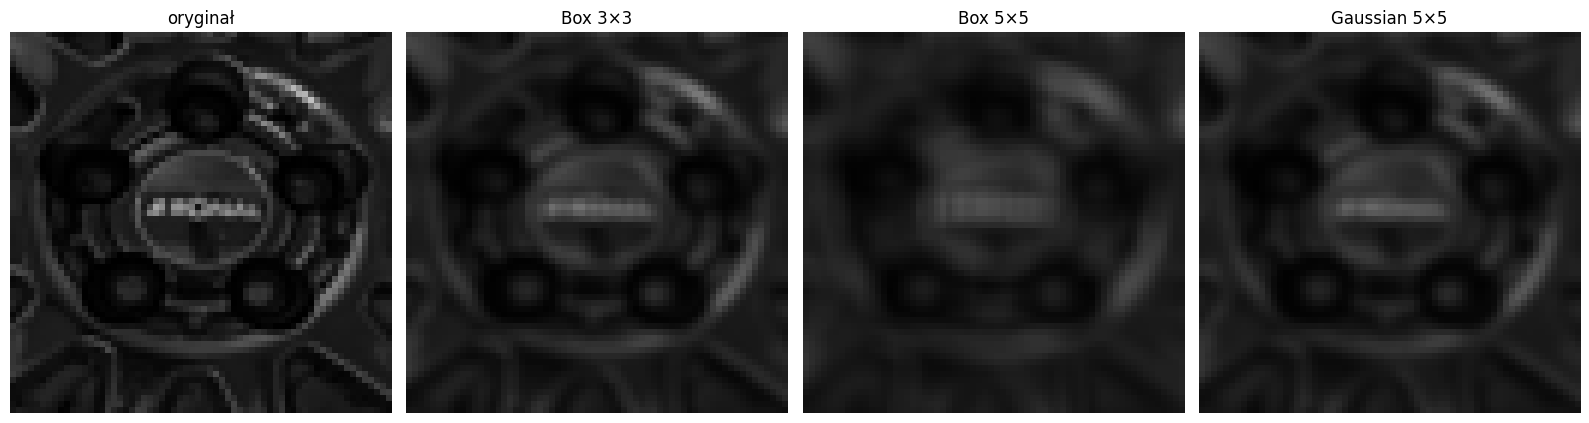

In [9]:
box3 = torch.ones(1,1,3,3) / 9
box5 = torch.ones(1,1,5,5) / 25
v = torch.tensor([1., 4., 6., 4., 1.])
gauss5 = (torch.outer(v, v) / 256).view(1,1,5,5)

blur_results = {"oryginał": gray}
for name, k in [("Box 3×3", box3), ("Box 5×5", box5), ("Gaussian 5×5", gauss5)]:
    out = F.conv2d(gray, k, stride=1, padding=k.shape[-1]//2, dilation=1)
    print(name, "| suma wag:", round(k.sum().item(), 4), "| rozmiar:", tuple(out.shape[-2:]))
    blur_results[name] = out

y0, x0, S = 80, 80, 64
fig, axes = plt.subplots(1, 4, figsize=(16, 4.4))
for ax, (name, out) in zip(axes, blur_results.items()):
    ax.imshow(out[0,0,y0:y0+S, x0:x0+S].detach(), cmap="gray", vmin=0, vmax=1, interpolation="nearest")
    ax.set_title(name); ax.axis("off")
plt.tight_layout(); plt.show()